# Stack Overflow Developer Survey Analysis

In [1]:
!pip -q install pandas numpy matplotlib seaborn scipy requests beautifulsoup4 lxml

## 1. Data Loading

In [2]:
import pandas as pd

url = "https://raw.githubusercontent.com/huyqng1412/stackoverflow_2025_project/main/survey_results_public.csv"

df = pd.read_csv(url, low_memory=False)

print("Dataset loaded successfully")
print("Shape:", df.shape)
print("Columns:", len(df.columns))
print("\nFirst 10 columns:")
print(df.columns[:10].tolist())

Dataset loaded successfully
Shape: (2, 1)
Columns: 1

First 10 columns:
['version https://git-lfs.github.com/spec/v1']


In [3]:
import requests
import zipfile
import io
import os

url = "https://github.com/isachenko-andrii/Stack-overflow-software-developer-survey-analysis/raw/refs/heads/main/data/raw/stack-overflow-developer-survey-2025.zip"

response = requests.get(url, timeout=180)

print("Status:", response.status_code)
print("Downloaded:", round(len(response.content) / (1024 * 1024), 2), "MB")

response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    print("\nFiles in ZIP:")
    for name in z.namelist():
        print(name)

Status: 200
Downloaded: 16.13 MB

Files in ZIP:
2025_Developer_Survey_Tool.pdf
survey_results_public.csv
survey_results_schema.csv


In [4]:
with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    z.extractall("stackoverflow_2025")

df = pd.read_csv(
    "stackoverflow_2025/survey_results_public.csv",
    low_memory=False
)

print("Dataset loaded successfully")
print("Shape:", df.shape)
print("Number of columns:", len(df.columns))
print("\nColumns:")
print(df.columns.tolist())

Dataset loaded successfully
Shape: (49191, 172)
Number of columns: 172

Columns:
['ResponseId', 'MainBranch', 'Age', 'EdLevel', 'Employment', 'EmploymentAddl', 'WorkExp', 'LearnCodeChoose', 'LearnCode', 'LearnCodeAI', 'AILearnHow', 'YearsCode', 'DevType', 'OrgSize', 'ICorPM', 'RemoteWork', 'PurchaseInfluence', 'TechEndorseIntro', 'TechEndorse_1', 'TechEndorse_2', 'TechEndorse_3', 'TechEndorse_4', 'TechEndorse_5', 'TechEndorse_6', 'TechEndorse_7', 'TechEndorse_8', 'TechEndorse_9', 'TechEndorse_13', 'TechEndorse_13_TEXT', 'TechOppose_1', 'TechOppose_2', 'TechOppose_3', 'TechOppose_5', 'TechOppose_7', 'TechOppose_9', 'TechOppose_11', 'TechOppose_13', 'TechOppose_16', 'TechOppose_15', 'TechOppose_15_TEXT', 'Industry', 'JobSatPoints_1', 'JobSatPoints_2', 'JobSatPoints_3', 'JobSatPoints_4', 'JobSatPoints_5', 'JobSatPoints_6', 'JobSatPoints_7', 'JobSatPoints_8', 'JobSatPoints_9', 'JobSatPoints_10', 'JobSatPoints_11', 'JobSatPoints_13', 'JobSatPoints_14', 'JobSatPoints_15', 'JobSatPoints_16', 

## 2. Data Preparation

In [5]:
project_df = df[
    [
        "ConvertedCompYearly",
        "Country",
        "DevType",
        "YearsCode",
        "LanguageHaveWorkedWith",
        "DatabaseHaveWorkedWith",
        "PlatformHaveWorkedWith"
    ]
].copy()

project_df.columns = [
    "Salary_USD",
    "Country",
    "Developer_Type",
    "Years_Code",
    "Languages",
    "Databases",
    "Cloud_Platforms"
]

print("Project dataset shape:", project_df.shape)
print("\nMissing values:")
print(project_df.isnull().sum())
print("\nPreview:")
display(project_df.head())

Project dataset shape: (49191, 7)

Missing values:
Salary_USD         25244
Country            13754
Developer_Type      5511
Years_Code          6149
Languages          17520
Databases          23641
Cloud_Platforms    24933
dtype: int64

Preview:


,Salary_USD,Country,Developer_Type,Years_Code,Languages,Databases,Cloud_Platforms
0,61256.0,Ukraine,"Developer, mobile",14.0,Bash/Shell (all shells);Dart;SQL,Cloud Firestore;PostgreSQL,Amazon Web Services (AWS);Cloudflare;Firebase;...
1,104413.0,Netherlands,"Developer, back-end",10.0,Java,Dynamodb;MongoDB,Amazon Web Services (AWS);Datadog;Docker;Homeb...
2,53061.0,Ukraine,"Developer, front-end",12.0,Dart;HTML/CSS;JavaScript;TypeScript,MongoDB;MySQL;PostgreSQL,Datadog;Firebase;npm;pnpm
3,36197.0,Ukraine,"Developer, back-end",5.0,Java;Kotlin;SQL,NaN,Amazon Web Services (AWS);Google Cloud
4,60000.0,Ukraine,Engineering manager,22.0,C;C#;C++;Delphi;HTML/CSS;Java;JavaScript;Lua;P...,Elasticsearch;Microsoft SQL Server;MySQL;Oracl...,Amazon Web Services (AWS);APT;Docker;Make;Mave...


In [6]:
project_df["Salary_USD"] = pd.to_numeric(
    project_df["Salary_USD"],
    errors="coerce"
)

project_df["Years_Code"] = pd.to_numeric(
    project_df["Years_Code"],
    errors="coerce"
)

salary_df = project_df[
    project_df["Salary_USD"].notna() &
    (project_df["Salary_USD"] > 0) &
    (project_df["Salary_USD"] < 1000000)
].copy()

salary_df.reset_index(drop=True, inplace=True)

print("Salary dataset shape:", salary_df.shape)
print("\nSalary statistics:")
print(salary_df["Salary_USD"].describe())

Salary dataset shape: (23893, 7)

Salary statistics:
count     23893.000000
mean      91298.927426
std       83338.668807
min           1.000000
25%       38000.000000
50%       75000.000000
75%      120000.000000
max      988273.000000
Name: Salary_USD, dtype: float64


## 3. Descriptive Statistics of Salary

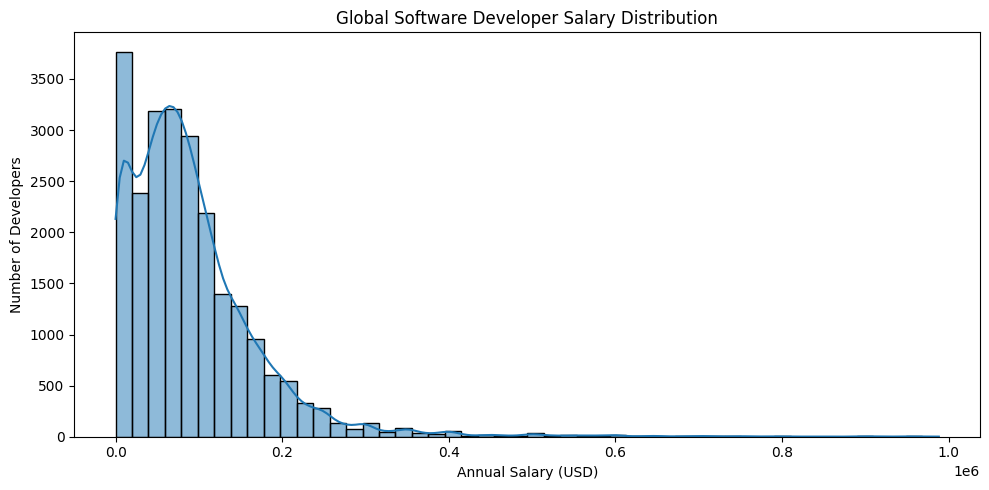

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.histplot(
    salary_df["Salary_USD"],
    bins=50,
    kde=True
)

plt.title("Global Software Developer Salary Distribution")
plt.xlabel("Annual Salary (USD)")
plt.ylabel("Number of Developers")

plt.tight_layout()
plt.show()

In [8]:
salary_stats = pd.DataFrame({
    "Statistic": [
        "Count",
        "Mean",
        "Median",
        "Standard Deviation",
        "Minimum",
        "25th Percentile",
        "75th Percentile",
        "Maximum",
        "Skewness"
    ],
    "Value": [
        salary_df["Salary_USD"].count(),
        salary_df["Salary_USD"].mean(),
        salary_df["Salary_USD"].median(),
        salary_df["Salary_USD"].std(),
        salary_df["Salary_USD"].min(),
        salary_df["Salary_USD"].quantile(0.25),
        salary_df["Salary_USD"].quantile(0.75),
        salary_df["Salary_USD"].max(),
        salary_df["Salary_USD"].skew()
    ]
})

display(salary_stats)

,Statistic,Value
0,Count,23893.000000
1,Mean,91298.927426
2,Median,75000.000000
3,Standard Deviation,83338.668807
4,Minimum,1.000000
5,25th Percentile,38000.000000
6,75th Percentile,120000.000000
7,Maximum,988273.000000
8,Skewness,2.829078


### Country-wise Salary Analysis

In [9]:
country_salary = (
    salary_df
    .dropna(subset=["Country"])
    .groupby("Country")["Salary_USD"]
    .agg(
        Developers="count",
        Mean_Salary="mean",
        Median_Salary="median",
        Std_Deviation="std"
    )
    .sort_values("Median_Salary", ascending=False)
)

country_salary_filtered = country_salary[
    country_salary["Developers"] >= 50
]

display(country_salary_filtered.head(20))

,Developers,Mean_Salary,Median_Salary,Std_Deviation
Country,,,,
United States of America,5222,163880.280352,150000.0,105330.214892
Switzerland,417,148679.800959,142592.0,84737.885925
Israel,177,131723.762712,141188.0,72553.201456
Ireland,154,121326.818182,116015.0,58124.873019
Denmark,229,99702.192140,98600.0,59067.749523
Australia,568,109278.348592,97514.0,71955.036865
United Kingdom of Great Britain and Northern Ireland,1481,106704.951384,94087.0,68098.011815
Singapore,64,131430.187500,92563.0,114791.486106
Norway,184,99256.809783,88945.0,75407.149887


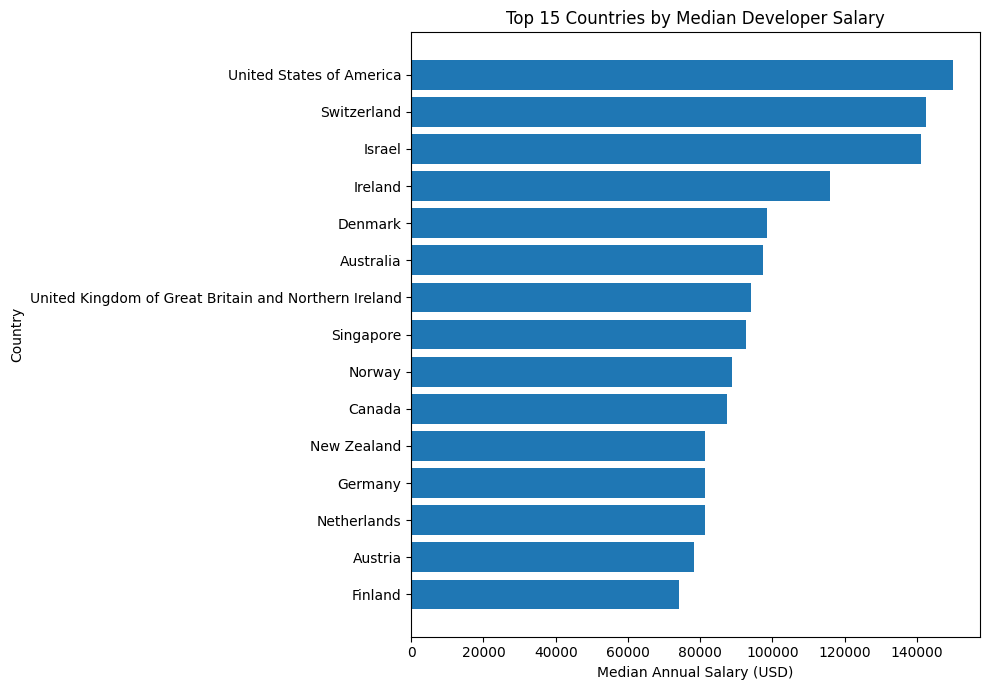

In [10]:
top_countries = country_salary_filtered.head(15).sort_values(
    "Median_Salary"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_countries.index,
    top_countries["Median_Salary"]
)

plt.title("Top 15 Countries by Median Developer Salary")
plt.xlabel("Median Annual Salary (USD)")
plt.ylabel("Country")

plt.tight_layout()
plt.show()

## 4. Correlation Between Years of Experience and Salary

In [11]:
experience_df = salary_df.dropna(
    subset=["Years_Code"]
).copy()

experience_df["Years_Code"] = pd.to_numeric(
    experience_df["Years_Code"],
    errors="coerce"
)

experience_df = experience_df[
    (experience_df["Years_Code"] >= 0) &
    (experience_df["Years_Code"] <= 50)
]

experience_salary = (
    experience_df
    .groupby("Years_Code")["Salary_USD"]
    .agg(
        Developers="count",
        Mean_Salary="mean",
        Median_Salary="median"
    )
)

display(experience_salary.head(15))

,Developers,Mean_Salary,Median_Salary
Years_Code,,,
1.0,188,24626.989362,5782.0
2.0,233,28071.334764,6961.0
3.0,431,25876.531323,11624.0
4.0,567,32562.617284,15082.0
5.0,879,40356.308305,26000.0
6.0,887,45666.019166,33403.0
7.0,903,53345.569214,40935.0
8.0,1113,57659.270440,45246.0
9.0,802,68301.997506,53218.0


In [12]:
correlation = experience_df[
    ["Years_Code", "Salary_USD"]
].corr()

print("Correlation Matrix:")
display(correlation)

r = correlation.loc[
    "Years_Code",
    "Salary_USD"
]

print(f"Pearson correlation coefficient: {r:.4f}")

Correlation Matrix:


,Years_Code,Salary_USD
Years_Code,1.000000,0.340043
Salary_USD,0.340043,1.000000


Pearson correlation coefficient: 0.3400


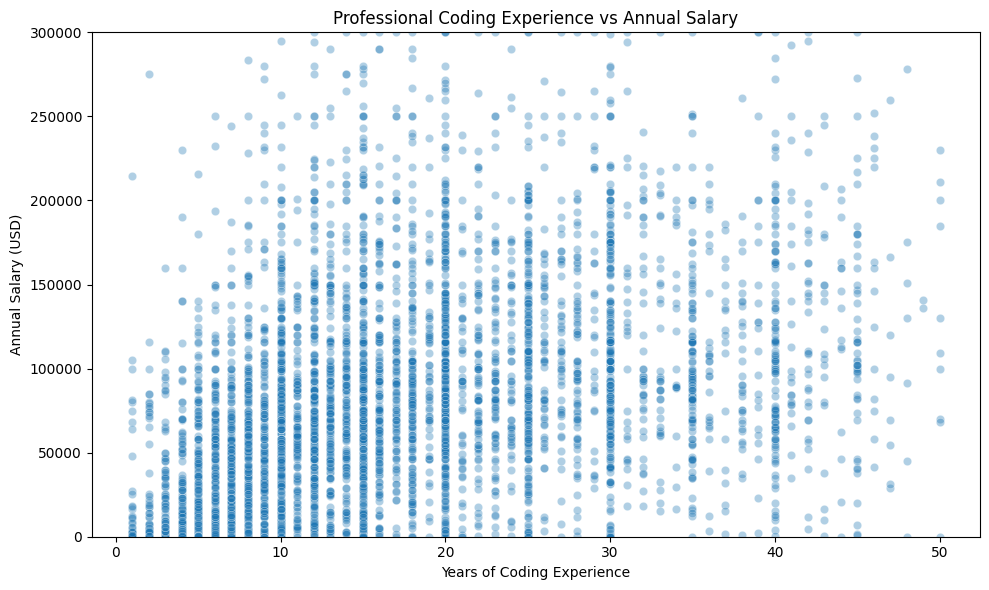

In [13]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=experience_df.sample(
        min(5000, len(experience_df)),
        random_state=42
    ),
    x="Years_Code",
    y="Salary_USD",
    alpha=0.35
)

plt.ylim(0, 300000)
plt.title("Professional Coding Experience vs Annual Salary")
plt.xlabel("Years of Coding Experience")
plt.ylabel("Annual Salary (USD)")

plt.tight_layout()
plt.show()

## 5. Sampling and Sampling Distributions

In [14]:
population = salary_df["Salary_USD"].dropna().reset_index(drop=True)

sample_size = 500

random_sample = population.sample(
    n=sample_size,
    random_state=42
)

print("Population size:", len(population))
print("Sample size:", len(random_sample))
print("Population mean:", round(population.mean(), 2))
print("Sample mean:", round(random_sample.mean(), 2))

Population size: 23893
Sample size: 500
Population mean: 91298.93
Sample mean: 96049.67


In [15]:
stratified_population = salary_df.dropna(
    subset=["Country"]
).copy()

country_counts = stratified_population["Country"].value_counts()

valid_countries = country_counts[
    country_counts >= 50
].index

stratified_population = stratified_population[
    stratified_population["Country"].isin(valid_countries)
]

n = 500

stratified_sample = (
    stratified_population
    .groupby("Country", group_keys=False)
    .apply(
        lambda x: x.sample(
            n=max(
                1,
                round(
                    len(x) /
                    len(stratified_population) *
                    n
                )
            ),
            random_state=42
        )
    )
)

stratified_sample = stratified_sample.sample(
    n=min(n, len(stratified_sample)),
    random_state=42
)

print("Stratified population:", len(stratified_population))
print("Stratified sample:", len(stratified_sample))
print("Stratified sample mean:", round(
    stratified_sample["Salary_USD"].mean(), 2
))

Stratified population: 22755
Stratified sample: 500
Stratified sample mean: 92588.96


/tmp/ipykernel_918/1068342904.py:20: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


### Central Limit Theorem Demonstration

In [16]:
import numpy as np
sample_sizes = [10, 30, 50, 100, 500]
simulations = 1000

sampling_distributions = {}

for n in sample_sizes:
    sample_means = []

    for _ in range(simulations):
        sample = population.sample(
            n=n,
            replace=False
        )
        sample_means.append(sample.mean())

    sampling_distributions[n] = np.array(sample_means)

print("Sampling distributions generated successfully")

for n in sample_sizes:
    print(
        f"n={n}: "
        f"mean={sampling_distributions[n].mean():.2f}, "
        f"std={sampling_distributions[n].std():.2f}"
    )

Sampling distributions generated successfully
n=10: mean=91441.32, std=26191.91
n=30: mean=90966.93, std=14783.72
n=50: mean=91668.87, std=12185.05
n=100: mean=90992.14, std=8200.54
n=500: mean=91482.53, std=3739.45


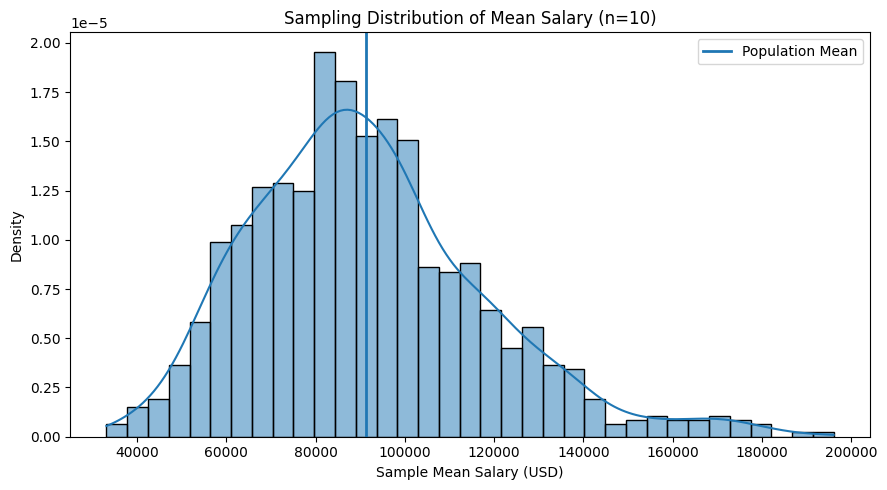

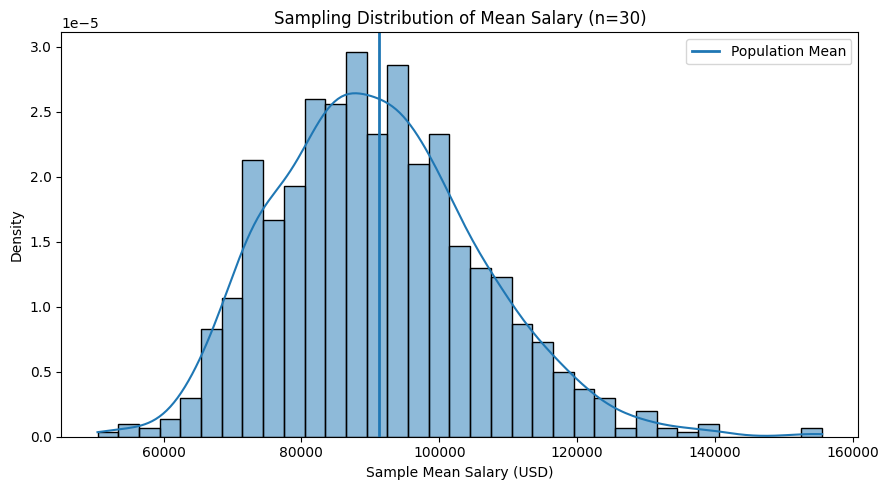

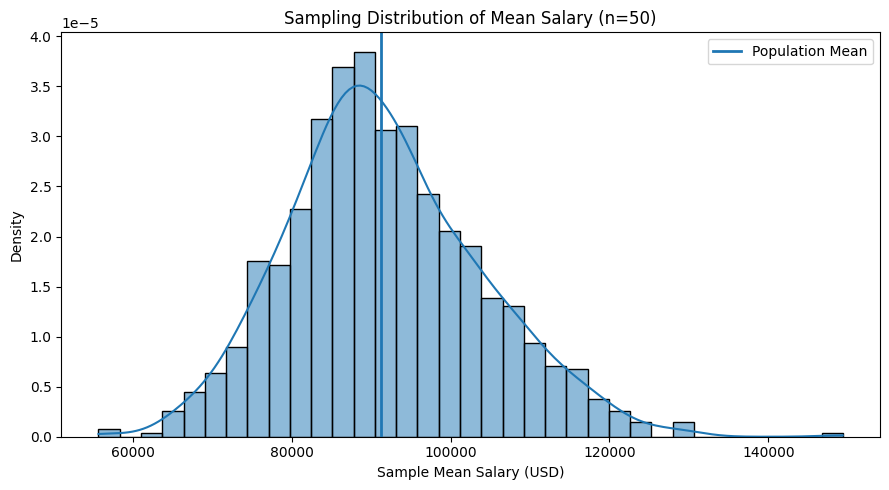

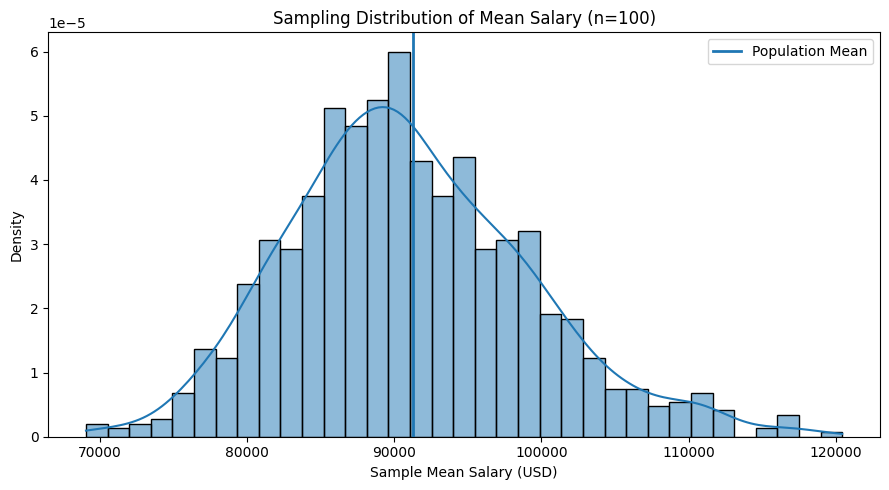

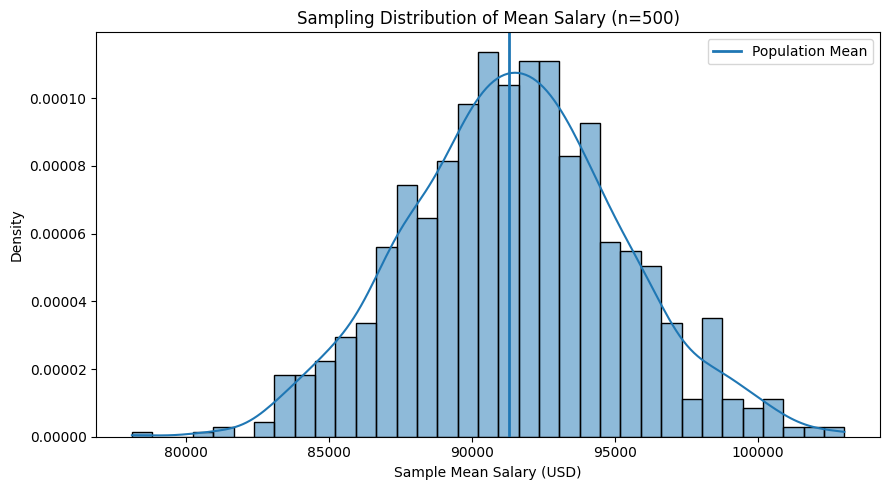

In [17]:
for n in sample_sizes:
    plt.figure(figsize=(9, 5))

    sns.histplot(
        sampling_distributions[n],
        bins=35,
        kde=True,
        stat="density"
    )

    plt.axvline(
        population.mean(),
        linewidth=2,
        label="Population Mean"
    )

    plt.title(
        f"Sampling Distribution of Mean Salary (n={n})"
    )
    plt.xlabel("Sample Mean Salary (USD)")
    plt.ylabel("Density")
    plt.legend()

    plt.tight_layout()
    plt.show()

## 6. Confidence Interval for Mean Salary

In [18]:
population_mean = population.mean()
population_std = population.std()

clt_results = []

for n in sample_sizes:
    sample_means = sampling_distributions[n]

    empirical_mean = sample_means.mean()
    empirical_se = sample_means.std(ddof=1)
    theoretical_se = population_std / np.sqrt(n)

    clt_results.append([
        n,
        empirical_mean,
        empirical_se,
        theoretical_se,
        abs(empirical_se - theoretical_se)
    ])

clt_results = pd.DataFrame(
    clt_results,
    columns=[
        "Sample_Size",
        "Mean_of_Sample_Means",
        "Empirical_SE",
        "Theoretical_SE",
        "SE_Difference"
    ]
)

display(clt_results.round(2))

,Sample_Size,Mean_of_Sample_Means,Empirical_SE,Theoretical_SE,SE_Difference
0,10,91441.32,26205.02,26354.00,148.98
1,30,90966.93,14791.12,15215.49,424.37
2,50,91668.87,12191.15,11785.87,405.28
3,100,90992.14,8204.65,8333.87,129.22
4,500,91482.53,3741.32,3727.02,14.30


In [19]:
from scipy import stats
sample = population.sample(
    n=500,
    random_state=42
)

sample_mean = sample.mean()
sample_std = sample.std(ddof=1)
n = len(sample)

confidence_level = 0.95
degrees_of_freedom = n - 1

standard_error = sample_std / np.sqrt(n)

t_critical = stats.t.ppf(
    1 - (1 - confidence_level) / 2,
    degrees_of_freedom
)

margin_of_error = t_critical * standard_error

lower_bound = sample_mean - margin_of_error
upper_bound = sample_mean + margin_of_error

print("Sample Mean:", round(sample_mean, 2))
print("Sample Standard Deviation:", round(sample_std, 2))
print("Standard Error:", round(standard_error, 2))
print("Margin of Error:", round(margin_of_error, 2))
print("95% Confidence Interval:")
print(
    f"({lower_bound:.2f}, {upper_bound:.2f})"
)


Sample Mean: 96049.67
Sample Standard Deviation: 81386.3
Standard Error: 3639.71
Margin of Error: 7151.04
95% Confidence Interval:
(88898.63, 103200.71)


## 7. Hypothesis Testing: India vs. USA Salaries

In [20]:
india = salary_df[
    salary_df["Country"] == "India"
]["Salary_USD"].dropna()

usa = salary_df[
    salary_df["Country"] == "United States of America"
]["Salary_USD"].dropna()

sample_size = 500

india_sample = india.sample(
    n=min(sample_size, len(india)),
    random_state=42
)

usa_sample = usa.sample(
    n=min(sample_size, len(usa)),
    random_state=42
)

t_statistic, p_value = stats.ttest_ind(
    india_sample,
    usa_sample,
    equal_var=False
)

print("India sample size:", len(india_sample))
print("USA sample size:", len(usa_sample))
print("India sample mean:", round(india_sample.mean(), 2))
print("USA sample mean:", round(usa_sample.mean(), 2))
print("t-statistic:", round(t_statistic, 4))
print("p-value:", p_value)

India sample size: 500
USA sample size: 500
India sample mean: 29601.46
USA sample mean: 165072.8
t-statistic: -26.728
p-value: 1.0338014372408478e-105


In [21]:
alpha = 0.05

if p_value < alpha:
    conclusion = "Reject H0"
else:
    conclusion = "Fail to reject H0"

print("Significance level:", alpha)
print("P-value:", f"{p_value:.6e}")
print("Decision:", conclusion)

if p_value < alpha:
    print("There is statistically significant evidence of a difference in mean salaries between India and the United States.")
else:
    print("There is insufficient statistical evidence of a difference in mean salaries between India and the United States.")

Significance level: 0.05
P-value: 1.033801e-105
Decision: Reject H0
There is statistically significant evidence of a difference in mean salaries between India and the United States.


## 8. Programming Language Popularity and Demand

In [22]:
language_data = df[
    ["LanguageHaveWorkedWith"]
].dropna().copy()

language_data["Language"] = language_data[
    "LanguageHaveWorkedWith"
].str.split(";")

language_data = language_data.explode("Language")

language_data["Language"] = language_data[
    "Language"
].str.strip()

language_counts = (
    language_data["Language"]
    .value_counts()
    .rename("Developers")
    .to_frame()
)

language_counts["Probability"] = (
    language_counts["Developers"] /
    len(df[df["LanguageHaveWorkedWith"].notna()])
)

language_counts["Percentage"] = (
    language_counts["Probability"] * 100
)

top_languages = language_counts.head(15)

display(top_languages)

,Developers,Probability,Percentage
Language,,,
JavaScript,21005,0.663225,66.322503
HTML/CSS,19698,0.621957,62.195700
SQL,18633,0.588330,58.833002
Python,18410,0.581289,58.128888
Bash/Shell (all shells),15503,0.489501,48.950144
TypeScript,13859,0.437593,43.759275
Java,9358,0.295475,29.547536
C#,8852,0.279499,27.949859
C++,7485,0.236336,23.633608


### Binomial Probability for Python Demand

In [23]:
from scipy.stats import binom

p_python = language_counts.loc["Python", "Probability"]
n = 20

k_values = np.arange(0, n + 1)

binomial_probabilities = binom.pmf(
    k_values,
    n,
    p_python
)

binomial_df = pd.DataFrame({
    "Python_Developers_in_Sample": k_values,
    "Probability": binomial_probabilities
})

display(binomial_df)

prob_at_least_10 = 1 - binom.cdf(
    9,
    n,
    p_python
)

print("Estimated probability of Python demand:", round(p_python, 4))
print(
    "Probability of at least 10 Python developers "
    "in a sample of 20:",
    round(prob_at_least_10, 4)
)

,Python_Developers_in_Sample,Probability
0,0,2.743405e-08
1,1,7.617237e-07
2,2,1.004613e-05
3,3,8.368110e-05
4,4,4.937349e-04
5,5,2.193417e-03
6,6,7.612702e-03
7,7,2.113715e-02
8,8,4.768450e-02
9,9,8.826600e-02


Estimated probability of Python demand: 0.5813
Probability of at least 10 Python developers in a sample of 20: 0.8325


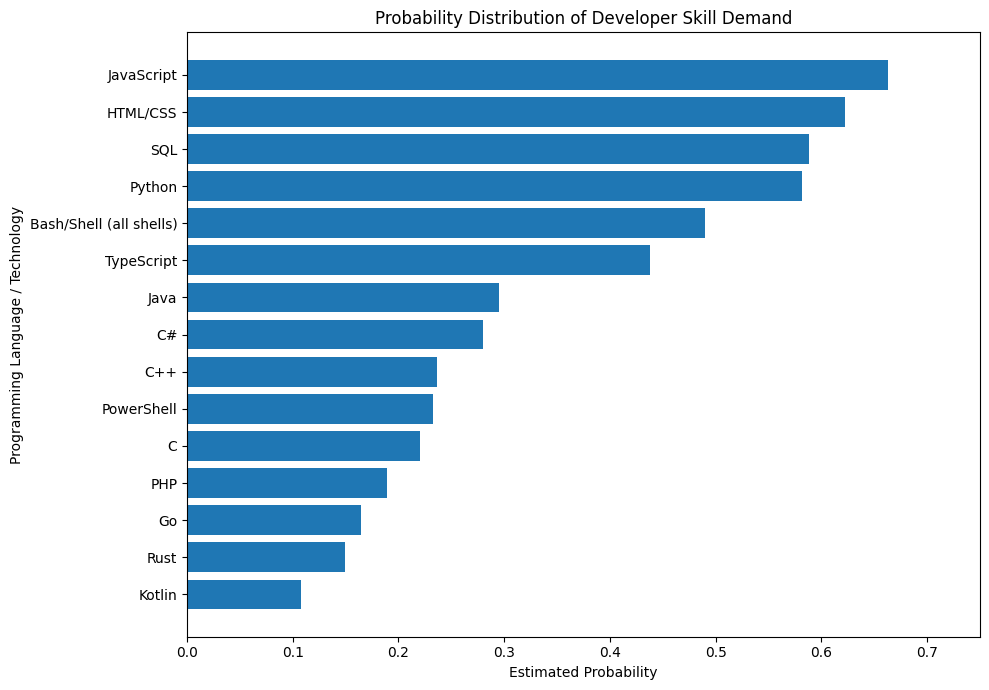

In [24]:
top_skill_data = language_counts.head(15).sort_values(
    "Probability"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_skill_data.index,
    top_skill_data["Probability"]
)

plt.title("Probability Distribution of Developer Skill Demand")
plt.xlabel("Estimated Probability")
plt.ylabel("Programming Language / Technology")

plt.xlim(0, 0.75)
plt.tight_layout()
plt.show()

## 9. Web Scraping for Survey Insights

In [25]:
import requests
from bs4 import BeautifulSoup

scrape_url = "https://survey.stackoverflow.co/2025/"

scrape_response = requests.get(
    scrape_url,
    headers={"User-Agent": "Mozilla/5.0"},
    timeout=60
)

print("Status:", scrape_response.status_code)

scrape_response.raise_for_status()

soup = BeautifulSoup(
    scrape_response.text,
    "html.parser"
)

title = soup.title.get_text(strip=True) if soup.title else "No title found"

headings = [
    h.get_text(" ", strip=True)
    for h in soup.find_all(["h1", "h2", "h3"])
]

print("Page title:", title)
print("Number of headings scraped:", len(headings))
print("\nFirst 15 headings:")

for heading in headings[:15]:
    print("-", heading)

Status: 200
Page title: 2025 Stack Overflow Developer Survey
Number of headings scraped: 26

First 15 headings:
- Visual Studio and Visual Studio Code both maintained their top spots for developer environments used for the fourth year
- One in four developers are happy at their current job
- Younger developers want developer content with social or interactive formats
- uv is the most admired SO tag technology this year
- Privacy, pricing and better alternatives are top reasons developers turn their back on a technology
- Python adoption grew in 2025
- More than one third of respondents use AI-enabled tools to learn AI this year
- 84% of respondents are using AI tools this year
- 66% of developers are frustrated with AI solutions that are almost right
- Respondents learning to code use YouTube for community more than professional developers
- Positive sentiment to AI tools has decreased in 2025
- More developers actively distrust the accuracy of AI tools than trust it
- A majority of de

In [26]:
scraped_data = pd.DataFrame({
    "Topic": headings,
    "Source_URL": scrape_url
})

scraped_data = scraped_data.drop_duplicates(
    subset=["Topic"]
).reset_index(drop=True)

print("Scraped records:", len(scraped_data))
display(scraped_data.head(10))


Scraped records: 26


,Topic,Source_URL
0,Visual Studio and Visual Studio Code both main...,https://survey.stackoverflow.co/2025/
1,One in four developers are happy at their curr...,https://survey.stackoverflow.co/2025/
2,Younger developers want developer content with...,https://survey.stackoverflow.co/2025/
3,uv is the most admired SO tag technology this ...,https://survey.stackoverflow.co/2025/
4,"Privacy, pricing and better alternatives are t...",https://survey.stackoverflow.co/2025/
5,Python adoption grew in 2025,https://survey.stackoverflow.co/2025/
6,More than one third of respondents use AI-enab...,https://survey.stackoverflow.co/2025/
7,84% of respondents are using AI tools this year,https://survey.stackoverflow.co/2025/
8,66% of developers are frustrated with AI solut...,https://survey.stackoverflow.co/2025/
9,Respondents learning to code use YouTube for c...,https://survey.stackoverflow.co/2025/


## 10. Python Developer Proportion Analysis

In [27]:
python_users = language_data[
    language_data["Language"] == "Python"
]

python_user_ids = set(
    df.index[df["LanguageHaveWorkedWith"].notna()]
)

python_developer_ids = set(
    python_users.index
)

python_rate = len(
    set(python_user_ids).intersection(python_developer_ids)
) / len(python_user_ids)

n = 500
simulations = 1000

sample_proportions = []

for _ in range(simulations):
    sample = np.random.binomial(
        1,
        python_rate,
        n
    )

    sample_proportions.append(
        sample.mean()
    )

sample_proportions = np.array(
    sample_proportions
)

theoretical_se = np.sqrt(
    python_rate * (1 - python_rate) / n
)

print("Estimated Python proportion:", round(python_rate, 4))
print("Mean of sample proportions:", round(
    sample_proportions.mean(), 4
))
print("Empirical standard error:", round(
    sample_proportions.std(ddof=1), 4
))
print("Theoretical standard error:", round(
    theoretical_se, 4
))

Estimated Python proportion: 0.5813
Mean of sample proportions: 0.5809
Empirical standard error: 0.0219
Theoretical standard error: 0.0221


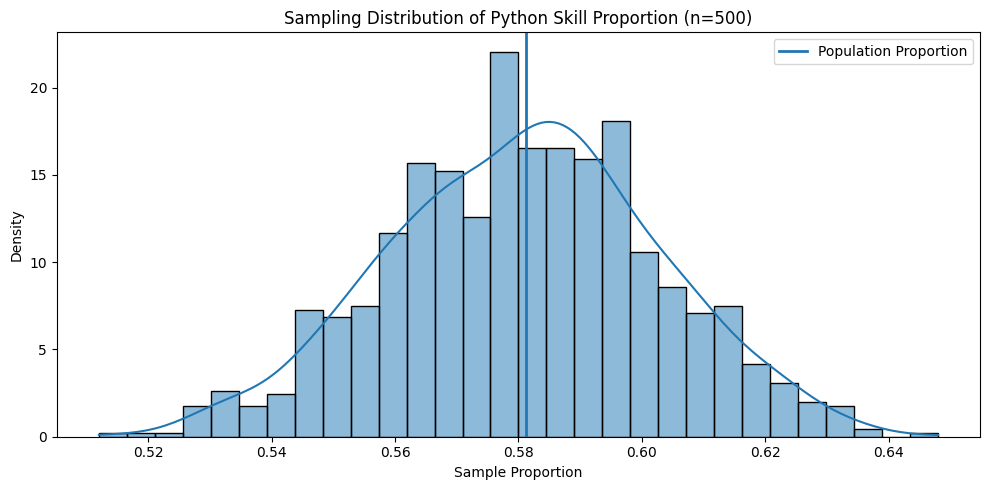

In [28]:
plt.figure(figsize=(10, 5))

sns.histplot(
    sample_proportions,
    bins=30,
    kde=True,
    stat="density"
)

plt.axvline(
    python_rate,
    linewidth=2,
    label="Population Proportion"
)

plt.title(
    "Sampling Distribution of Python Skill Proportion (n=500)"
)
plt.xlabel("Sample Proportion")
plt.ylabel("Density")
plt.legend()

plt.tight_layout()
plt.show()

In [29]:
from scipy import stats

x = round(python_rate * len(python_user_ids))
n = len(python_user_ids)

sample_proportion = x / n

z_critical = stats.norm.ppf(0.975)

proportion_se = np.sqrt(
    sample_proportion * (1 - sample_proportion) / n
)

margin_of_error = z_critical * proportion_se

lower = sample_proportion - margin_of_error
upper = sample_proportion + margin_of_error

print("Python skill proportion:", round(sample_proportion, 4))
print("Sample size:", n)
print("Standard Error:", round(proportion_se, 6))
print("Margin of Error:", round(margin_of_error, 6))
print("95% Confidence Interval:")
print(f"({lower:.4f}, {upper:.4f})")

Python skill proportion: 0.5813
Sample size: 31671
Standard Error: 0.002772
Margin of Error: 0.005433
95% Confidence Interval:
(0.5759, 0.5867)


## 11. Comparison of Sampling Methods

In [30]:
python_mask = df["LanguageHaveWorkedWith"].fillna("").str.contains(
    r"(^|;)Python(;|$)",
    regex=True
)

python_count = python_mask.sum()
python_total = df["LanguageHaveWorkedWith"].notna().sum()

python_rate = python_count / python_total

print("Developers reporting Python:", python_count)
print("Developers with language data:", python_total)
print("Estimated Python skill probability:", round(python_rate, 4))
print("Estimated percentage:", round(python_rate * 100, 2), "%")

Developers reporting Python: 18410
Developers with language data: 31671
Estimated Python skill probability: 0.5813
Estimated percentage: 58.13 %


/tmp/ipykernel_918/4268220249.py:1: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  python_mask = df["LanguageHaveWorkedWith"].fillna("").str.contains(


In [31]:
sampling_interval = len(population) // sample_size
start = np.random.randint(0, sampling_interval)
systematic_indices = np.arange(start, len(population), sampling_interval)
systematic_sample = population.iloc[systematic_indices]

print("Systematic sample size:", len(systematic_sample))
print("Systematic sample mean:", round(systematic_sample.mean(), 2))

Systematic sample size: 508
Systematic sample mean: 89875.65


In [32]:
sampling_comparison = pd.DataFrame({
    "Sampling_Method": [
        "Population",
        "Simple Random Sampling",
        "Systematic Sampling",
        "Stratified Sampling"
    ],
    "Sample_Size": [
        len(population),
        len(random_sample),
        len(systematic_sample),
        len(stratified_sample)
    ],
    "Mean_Salary": [
        population.mean(),
        random_sample.mean(),
        systematic_sample.mean(),
        stratified_sample["Salary_USD"].mean()
    ]
})

sampling_comparison["Absolute_Error"] = (
    sampling_comparison["Mean_Salary"] -
    population.mean()
).abs()

display(
    sampling_comparison.round(2)
)

,Sampling_Method,Sample_Size,Mean_Salary,Absolute_Error
0,Population,23893,91298.93,0.00
1,Simple Random Sampling,500,96049.67,4750.74
2,Systematic Sampling,508,89875.65,1423.28
3,Stratified Sampling,500,92588.96,1290.04


## 12. Central Limit Theorem Summary

In [33]:
clt_summary = clt_results.copy()

clt_summary["Relative_SE_Error_%"] = (
    abs(
        clt_summary["Empirical_SE"] -
        clt_summary["Theoretical_SE"]
    ) /
    clt_summary["Theoretical_SE"]
) * 100

display(
    clt_summary.round(2)
)

,Sample_Size,Mean_of_Sample_Means,Empirical_SE,Theoretical_SE,SE_Difference,Relative_SE_Error_%
0,10,91441.32,26205.02,26354.00,148.98,0.57
1,30,90966.93,14791.12,15215.49,424.37,2.79
2,50,91668.87,12191.15,11785.87,405.28,3.44
3,100,90992.14,8204.65,8333.87,129.22,1.55
4,500,91482.53,3741.32,3727.02,14.30,0.38


## 13. Top Programming Skills by Salary

In [34]:
top_languages_list = language_counts.head(10).index.tolist()

skill_salary = []

for language in top_languages_list:
    mask = salary_df["Languages"].fillna("").str.contains(
        rf"(^|;){language}(;|$)",
        regex=True
    )

    salaries = salary_df.loc[
        mask,
        "Salary_USD"
    ]

    skill_salary.append([
        language,
        len(salaries),
        salaries.mean(),
        salaries.median()
    ])

skill_salary = pd.DataFrame(
    skill_salary,
    columns=[
        "Language",
        "Developers",
        "Mean_Salary",
        "Median_Salary"
    ]
)

skill_salary = skill_salary.sort_values(
    "Median_Salary",
    ascending=False
)

display(skill_salary.round(2))

/tmp/ipykernel_918/3879909391.py:6: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  mask = salary_df["Languages"].fillna("").str.contains(


,Language,Developers,Mean_Salary,Median_Salary
9,PowerShell,5329,91354.27,80984.0
5,TypeScript,10317,94566.08,79141.0
7,C#,6384,90959.78,78488.5
3,Python,12707,96088.08,76570.0
2,SQL,13522,92169.72,76239.0
0,JavaScript,14849,90740.47,75294.0
6,Java,6270,93338.93,75000.0
1,HTML/CSS,13759,88497.34,73785.0
8,C++,4083,93018.79,72815.0
4,Bash/Shell (all shells),0,NaN,NaN


In [35]:
skill_salary = []

for language in top_languages_list:
    mask = salary_df["Languages"].fillna("").apply(
        lambda x: language in [item.strip() for item in x.split(";")]
    )

    salaries = salary_df.loc[mask, "Salary_USD"].dropna()

    skill_salary.append([
        language,
        len(salaries),
        salaries.mean(),
        salaries.median()
    ])

skill_salary = pd.DataFrame(
    skill_salary,
    columns=[
        "Language",
        "Developers",
        "Mean_Salary",
        "Median_Salary"
    ]
)

skill_salary = skill_salary.sort_values(
    "Median_Salary",
    ascending=False
)

display(skill_salary.round(2))

,Language,Developers,Mean_Salary,Median_Salary
4,Bash/Shell (all shells),11083,100645.60,83507.0
9,PowerShell,5329,91354.27,80984.0
5,TypeScript,10317,94566.08,79141.0
7,C#,6384,90959.78,78488.5
3,Python,12707,96088.08,76570.0
2,SQL,13522,92169.72,76239.0
0,JavaScript,14849,90740.47,75294.0
6,Java,6270,93338.93,75000.0
8,C++,4593,94402.87,74000.0
1,HTML/CSS,13759,88497.34,73785.0


In [36]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import seaborn as sns
import matplotlib.pyplot as plt

# -------------------------------------------------------------------
# 1. LAB 5: One-Sample Z-Test & t-Test + 95% Confidence Intervals
# -------------------------------------------------------------------
salary_clean = salary_df["Salary_USD"].dropna()
sample_mean = salary_clean.mean()
sample_std = salary_clean.std()
n = len(salary_clean)

# 95% Confidence Interval for Population Mean Salary
ci_95 = stats.t.interval(0.95, df=n-1, loc=sample_mean, scale=sample_std/np.sqrt(n))
print(f"95% Confidence Interval for Salary: ${ci_95[0]:,.2f} to ${ci_95[1]:,.2f}")

# One-Sample t-Test (Hypothesized mean salary = $90,000)
pop_mean_hypo = 90000
t_stat, p_val_t = stats.ttest_1samp(salary_clean, pop_mean_hypo)
print(f"One-Sample t-test: t = {t_stat:.4f}, p-value = {p_val_t:.4e}")

# One-Sample Z-Test (using sample std as population std proxy due to large n)
z_stat = (sample_mean - pop_mean_hypo) / (sample_std / np.sqrt(n))
p_val_z = 2 * (1 - stats.norm.cdf(abs(z_stat)))
print(f"One-Sample Z-test: Z = {z_stat:.4f}, p-value = {p_val_z:.4e}\n")


# -------------------------------------------------------------------
# 2. PRACTICAL 6 PART B: Covariance & Correlation Analysis
# -------------------------------------------------------------------
corr_df = salary_df[["Years_Code", "Salary_USD"]].dropna()

cov_matrix = np.cov(corr_df["Years_Code"], corr_df["Salary_USD"])
cov_val = cov_matrix[0, 1]

pearson_r, p_val_pearson = stats.pearsonr(corr_df["Years_Code"], corr_df["Salary_USD"])
spearman_rho, p_val_spearman = stats.spearmanr(corr_df["Years_Code"], corr_df["Salary_USD"])

print(f"Covariance (Years_Code vs Salary): {cov_val:,.2f}")
print(f"Pearson Correlation (r): {pearson_r:.4f} (p-value: {p_val_pearson:.4e})")
print(f"Spearman Correlation (rho): {spearman_rho:.4f} (p-value: {p_val_spearman:.4e})\n")


# -------------------------------------------------------------------
# 3. CHI-SQUARE TEST & ONE-WAY ANOVA
# -------------------------------------------------------------------
# Chi-Square Test of Independence: MainBranch vs Employment
chi_data = df[["MainBranch", "Employment"]].dropna()
contingency_table = pd.crosstab(chi_data["MainBranch"], chi_data["Employment"])

chi2_stat, p_val_chi2, dof, expected = stats.chi2_contingency(contingency_table)
print(f"Chi-Square Test: Chi2 = {chi2_stat:.4f}, dof = {dof}, p-value = {p_val_chi2:.4e}")

# One-Way ANOVA: Salary across top Developer Types
top_devs = salary_df["Developer_Type"].value_counts().head(4).index
anova_groups = [salary_df[salary_df["Developer_Type"] == dev]["Salary_USD"].dropna() for dev in top_devs]

f_stat, p_val_anova = stats.f_oneway(*anova_groups)
print(f"One-Way ANOVA across Top Dev Types: F-stat = {f_stat:.4f}, p-value = {p_val_anova:.4e}")

95% Confidence Interval for Salary: $90,242.16 to $92,355.70
One-Sample t-test: t = 2.4092, p-value = 1.5995e-02
One-Sample Z-test: Z = 2.4092, p-value = 1.5987e-02

Covariance (Years_Code vs Salary): 305,023.46
Pearson Correlation (r): 0.3312 (p-value: 0.0000e+00)
Spearman Correlation (rho): 0.4627 (p-value: 0.0000e+00)

Chi-Square Test: Chi2 = 17494.3151, dof = 25, p-value = 0.0000e+00
One-Way ANOVA across Top Dev Types: F-stat = 104.3443, p-value = 8.2245e-67


In [42]:
import subprocess
import sys
import os
from pyngrok import ngrok, exception

# Configure ngrok auth token
NGROK_TOKEN = "3LJebZqoIyCQjbGv9ukklYprLiQ_3dexdMeDJeiSxPaTUJAJC"
try:
    ngrok.set_auth_token(NGROK_TOKEN)
except exception.PyngrokNgrokError as e:
    print("Ngrok token already set, continuing...")

# Terminate any existing tunnels
ngrok.kill()

# Start Streamlit app in background if not already running
subprocess.Popen([sys.executable, "-m", "streamlit", "run", "app.py", "--server.port", "8501"])

# Open an HTTP tunnel on port 8501
try:
    public_url = ngrok.connect(8501, "http")
    print(f"Streamlit dashboard has launched successfully via ngrok!")
    print(f"Access your public interface here: {public_url}")
except Exception as e:
    print(f"Ngrok tunnel failed: {e}. You can fall back to localtunnel below.")

Ngrok token already set, continuing...
Streamlit dashboard has launched successfully via ngrok!
Access your public interface here: NgrokTunnel: "https://comfy-versus-bladder.ngrok-free.dev" -> "http://localhost:8501"


In [44]:
# Fetch external IP for localtunnel authorization
import urllib.request
print("Your Tunnel IP Password is:", urllib.request.urlopen('https://ipv4.icanhazip.com').read().decode('utf8').strip())

Your Tunnel IP Password is: 34.21.1.214


In [45]:
# Install streamlit and localtunnel to expose the dashboard
!npm install -g localtunnel
!pip -q install streamlit

⠙⠹⠸⠼⠴⠦
changed 22 packages in 861ms
⠦
⠦3 packages are looking for funding
⠦  run `npm fund` for details
⠦

In [48]:
%%writefile app.py

import streamlit as st
import pandas as pd
import numpy as np
import joblib

st.set_page_config(
    page_title="Career Analytics | Developer Insights",
    page_icon="📈",
    layout="wide",
    initial_sidebar_state="expanded"
)

# ── Professional light theme ────────────────────────────────────────────────

st.markdown("""
<link rel="preconnect" href="https://fonts.googleapis.com">
<link rel="preconnect" href="https://fonts.gstatic.com" crossorigin>
<link href="https://fonts.googleapis.com/css2?family=Inter:wght@400;500;600;700;800&family=Material+Symbols+Rounded:opsz,wght,FILL,GRAD@20..48,400,0,0" rel="stylesheet">

<style>
:root {
    color-scheme: light;
    --ink: #172033;
    --muted: #596579;
    --line: #E1E7F0;
    --canvas: #F5F7FB;
    --surface: #FFFFFF;
    --primary: #3157D5;
    --primary-dark: #2446B8;
    --soft-blue: #EEF3FF;
    --green: #13764F;
    --amber: #975A08;
}

html, body, .stApp, [data-testid="stAppViewContainer"] {
    background-color: var(--canvas) !important;
    color: var(--ink) !important;
    font-family: 'Inter', Arial, sans-serif !important;
}

[data-testid="stAppViewContainer"] *,
[data-testid="stSidebar"] * {
    color: var(--ink);
}

[data-testid="stHeader"] {
    background: rgba(245,247,251,0.96) !important;
}

[data-testid="stAppViewContainer"] > .main .block-container {
    max-width: 1500px;
    padding-top: 1.6rem;
    padding-bottom: 3rem;
}

/* Sidebar */

[data-testid="stSidebar"] {
    background: #FFFFFF !important;
    border-right: 1px solid var(--line);
}

[data-testid="stSidebar"] p,
[data-testid="stSidebar"] span,
[data-testid="stSidebar"] label,
[data-testid="stSidebar"] div,
[data-testid="stSidebar"] h1,
[data-testid="stSidebar"] h2,
[data-testid="stSidebar"] h3 {
    color: var(--ink);
}

[data-testid="stSidebar"] [data-testid="stCaptionContainer"],
[data-testid="stSidebar"] [data-testid="stCaptionContainer"] p {
    color: var(--muted) !important;
}

/* Typography */

h1, h2, h3, h4, h5, h6,
.stMarkdown h1, .stMarkdown h2, .stMarkdown h3,
.stMarkdown p, .stMarkdown li {
    color: var(--ink) !important;
}

p, label, li, .stCaption, [data-testid="stCaptionContainer"] p {
    color: var(--muted);
}

.material-symbols-rounded {
    font-variation-settings: 'FILL' 0, 'wght' 450, 'GRAD' 0, 'opsz' 24;
    vertical-align: middle;
}

/* Brand */

.brand {
    display: flex;
    align-items: center;
    gap: 12px;
    padding: 7px 0 22px;
}

.brand-mark {
    display: flex;
    align-items: center;
    justify-content: center;
    width: 44px;
    height: 44px;
    border-radius: 13px;
    background: linear-gradient(135deg, #4568E8, #2948B8);
    box-shadow: 0 7px 18px rgba(49,87,213,.20);
}

.brand-mark .material-symbols-rounded {
    color: #FFFFFF !important;
}

.brand-title {
    font-size: 1.05rem;
    font-weight: 800;
    color: var(--ink) !important;
}

.brand-subtitle {
    font-size: .76rem;
    color: var(--muted) !important;
    margin-top: 3px;
}

/* Header */

.hero {
    padding: 26px 28px;
    border: 1px solid var(--line);
    border-radius: 18px;
    background: linear-gradient(110deg, #FFFFFF 0%, #F0F4FF 100%);
    margin-bottom: 22px;
}

.eyebrow {
    text-transform: uppercase;
    letter-spacing: .12em;
    font-size: .72rem;
    color: var(--primary) !important;
    font-weight: 800;
    margin-bottom: 9px;
}

.hero-title {
    font-size: 1.8rem;
    line-height: 1.2;
    font-weight: 800;
    letter-spacing: -.045em;
    color: var(--ink) !important;
}

.hero-copy {
    color: var(--muted) !important;
    margin-top: 9px;
    font-size: .94rem;
    line-height: 1.65;
    max-width: 760px;
}

/* Status */

.status-pill {
    display: inline-flex;
    align-items: center;
    gap: 7px;
    border-radius: 99px;
    padding: 7px 11px;
    font-size: .78rem;
    font-weight: 700;
    border: 1px solid transparent;
}

.status-dot {
    width: 7px;
    height: 7px;
    border-radius: 50%;
    display: inline-block;
}

/* Section headings */

.section-heading {
    display: flex;
    align-items: center;
    gap: 9px;
    margin: 10px 0 14px;
    font-size: 1.08rem;
    font-weight: 750;
    color: var(--ink) !important;
}

.section-icon {
    width: 33px;
    height: 33px;
    display: inline-flex;
    align-items: center;
    justify-content: center;
    border-radius: 9px;
    background: var(--soft-blue);
    color: var(--primary) !important;
}

.section-icon .material-symbols-rounded {
    color: var(--primary) !important;
}

/* KPI cards */

.kpi {
    background: #FFFFFF;
    border: 1px solid var(--line);
    border-radius: 15px;
    padding: 17px 18px;
    min-height: 126px;
    box-shadow: 0 2px 8px rgba(16,24,40,.025);
}

.kpi-label {
    color: var(--muted) !important;
    font-size: .79rem;
    font-weight: 600;
    margin-bottom: 12px;
}

.kpi-value {
    color: var(--ink) !important;
    font-size: 1.55rem;
    font-weight: 800;
    letter-spacing: -.04em;
    line-height: 1.2;
}

.kpi-foot {
    color: var(--muted) !important;
    font-size: .75rem;
    margin-top: 9px;
}

/* Panels */

.panel {
    background: #FFFFFF;
    border: 1px solid var(--line);
    border-radius: 15px;
    padding: 20px;
}

/* Input labels */

.stTextInput label,
.stTextArea label,
.stSelectbox label,
.stSlider label,
.stNumberInput label,
.stRadio label,
.stCheckbox label,
[data-testid="stWidgetLabel"],
[data-testid="stWidgetLabel"] p {
    color: var(--ink) !important;
    font-weight: 600 !important;
}

/* Text inputs */

.stTextInput input,
.stTextArea textarea,
.stNumberInput input,
[data-baseweb="input"] input,
[data-baseweb="textarea"] textarea {
    color: #172033 !important;
    -webkit-text-fill-color: #172033 !important;
    background-color: #FFFFFF !important;
    caret-color: #3157D5 !important;
    border-color: #D0D7E2 !important;
}

.stTextInput input::placeholder,
.stTextArea textarea::placeholder,
[data-baseweb="input"] input::placeholder,
[data-baseweb="textarea"] textarea::placeholder {
    color: #7A8495 !important;
    -webkit-text-fill-color: #7A8495 !important;
    opacity: 1 !important;
}

/* Selectbox selected value */

div[data-baseweb="select"] > div {
    background-color: #FFFFFF !important;
    border: 1px solid #D0D7E2 !important;
    border-radius: 9px !important;
    color: #172033 !important;
}

div[data-baseweb="select"] input,
div[data-baseweb="select"] span,
div[data-baseweb="select"] div[class*="singleValue"],
div[data-baseweb="select"] div[class*="placeholder"] {
    color: #172033 !important;
    -webkit-text-fill-color: #172033 !important;
}

div[data-baseweb="select"] svg {
    fill: #596579 !important;
    color: #596579 !important;
}

/* Selectbox dropdown menu */

div[data-baseweb="popover"],
div[data-baseweb="popover"] > div,
div[data-baseweb="menu"],
ul[role="listbox"],
div[role="listbox"] {
    background-color: #FFFFFF !important;
    color: #172033 !important;
}

div[role="option"],
div[role="option"] > div,
div[role="option"] span {
    background-color: #FFFFFF !important;
    color: #172033 !important;
    -webkit-text-fill-color: #172033 !important;
}

div[role="option"]:hover,
div[role="option"]:hover * {
    background-color: #EEF3FF !important;
    color: #2446B8 !important;
    -webkit-text-fill-color: #2446B8 !important;
}

div[aria-selected="true"],
div[aria-selected="true"] * {
    background-color: #EEF3FF !important;
    color: #2446B8 !important;
    -webkit-text-fill-color: #2446B8 !important;
}

div[data-baseweb="select"] input {
    background-color: #FFFFFF !important;
    color: #172033 !important;
    -webkit-text-fill-color: #172033 !important;
}

/* Slider */

[data-testid="stSlider"] {
    color: var(--primary) !important;
}

[data-testid="stSlider"] [data-testid="stTickBar"] div,
[data-testid="stSlider"] p {
    color: var(--muted) !important;
}

/* Buttons */

.stButton > button {
    background: var(--primary) !important;
    color: #FFFFFF !important;
    border: 1px solid var(--primary) !important;
    border-radius: 9px !important;
    min-height: 43px;
    font-weight: 700 !important;
    transition: all .15s ease;
}

.stButton > button * {
    color: #FFFFFF !important;
}

.stButton > button:hover {
    background: var(--primary-dark) !important;
    border-color: var(--primary-dark) !important;
    box-shadow: 0 5px 14px rgba(49,87,213,.18);
}

/* Tabs */

.stTabs [data-baseweb="tab-list"] {
    gap: 8px;
    background: #E9EDF5;
    padding: 5px;
    border-radius: 11px;
}

.stTabs [data-baseweb="tab"] {
    height: 43px;
    border-radius: 8px;
    padding: 0 16px;
    color: #475467 !important;
    font-weight: 650;
}

.stTabs [data-baseweb="tab"] p,
.stTabs [data-baseweb="tab"] span {
    color: #475467 !important;
}

.stTabs [data-baseweb="tab"][aria-selected="true"] {
    background: #FFFFFF !important;
    color: var(--primary) !important;
    box-shadow: 0 1px 4px rgba(16,24,40,.10);
}

.stTabs [data-baseweb="tab"][aria-selected="true"] p,
.stTabs [data-baseweb="tab"][aria-selected="true"] span {
    color: var(--primary) !important;
}

/* Dataframes and tables */

[data-testid="stDataFrame"],
[data-testid="stTable"] {
    background: #FFFFFF !important;
    border: 1px solid var(--line);
    border-radius: 11px;
    overflow: hidden;
}

[data-testid="stDataFrame"] *,
[data-testid="stTable"] * {
    color: #172033 !important;
}

/* Metrics */

[data-testid="stMetric"] {
    background: #FFFFFF !important;
    border: 1px solid var(--line);
    border-radius: 13px;
    padding: 16px;
}

[data-testid="stMetric"] label,
[data-testid="stMetricLabel"],
[data-testid="stMetricLabel"] * {
    color: var(--muted) !important;
}

[data-testid="stMetricValue"],
[data-testid="stMetricValue"] * {
    color: var(--ink) !important;
}

/* Alerts */

[data-testid="stAlert"] {
    border-radius: 11px;
}

[data-testid="stAlert"] p,
[data-testid="stAlert"] span {
    color: #172033 !important;
}

/* Expanders */

[data-testid="stExpander"] {
    background: #FFFFFF !important;
    border: 1px solid var(--line) !important;
    border-radius: 10px !important;
}

[data-testid="stExpander"] summary,
[data-testid="stExpander"] summary span,
[data-testid="stExpander"] summary p {
    color: var(--ink) !important;
}

/* Footer */

hr {
    border-color: var(--line) !important;
}

.footer {
    color: #7B8495 !important;
    font-size: .75rem;
    text-align: center;
    padding-top: 24px;
}

@media (max-width: 760px) {
    [data-testid="stAppViewContainer"] > .main .block-container {
        padding: 1rem .8rem 2rem;
    }

    .hero {
        padding: 20px;
    }

    .hero-title {
        font-size: 1.45rem;
    }
}
</style>
""", unsafe_allow_html=True)


# ── Load trained models ─────────────────────────────────────────────────────

try:
    reg_model = joblib.load("best_salary_regression_model.pkl")
    clf_model = joblib.load("best_salary_classifier_model.pkl")
    models_loaded = True

except Exception as e:
    models_loaded = False
    reg_model = None
    clf_model = None


# ── Benchmark data ──────────────────────────────────────────────────────────

regression_perf = pd.DataFrame([
    {"Model": "Ridge Regression", "R2 Score": 0.3680, "RMSE": 71092.50, "MAE": 42870.58},
    {"Model": "Multiple Linear Regression", "R2 Score": 0.3679, "RMSE": 71092.82, "MAE": 42872.01},
    {"Model": "Lasso Regression", "R2 Score": 0.3673, "RMSE": 71128.53, "MAE": 42888.39},
    {"Model": "Random Forest Regressor", "R2 Score": 0.3436, "RMSE": 72451.69, "MAE": 43197.31},
    {"Model": "Decision Tree Regressor", "R2 Score": 0.3005, "RMSE": 74792.27, "MAE": 44224.36}
])

classification_perf = pd.DataFrame([
    {"Model": "Support Vector Machine", "Accuracy": 0.8269, "Precision": 0.8348, "Recall": 0.8926, "F1-Score": 0.8627, "ROC-AUC": 0.8629},
    {"Model": "Random Forest Classifier", "Accuracy": 0.8172, "Precision": 0.8230, "Recall": 0.8919, "F1-Score": 0.8561, "ROC-AUC": 0.8967},
    {"Model": "Logistic Regression", "Accuracy": 0.8190, "Precision": 0.8374, "Recall": 0.8724, "F1-Score": 0.8545, "ROC-AUC": 0.8904},
    {"Model": "Decision Tree Classifier", "Accuracy": 0.8111, "Precision": 0.8121, "Recall": 0.8976, "F1-Score": 0.8527, "ROC-AUC": 0.8804},
    {"Model": "K-Nearest Neighbors", "Accuracy": 0.8036, "Precision": 0.8224, "Recall": 0.8645, "F1-Score": 0.8429, "ROC-AUC": 0.8655}
])


# ── Simulated job pool ──────────────────────────────────────────────────────

pending_job_pool = [
    {
        "title": "Senior Backend Engineer",
        "country": "United States of America",
        "dev_type": "Developer, back-end",
        "skills": "Python;SQL;Docker;AWS",
        "salary": 165000
    },
    {
        "title": "Full Stack Developer",
        "country": "Germany",
        "dev_type": "Developer, full-stack",
        "skills": "JavaScript;HTML/CSS;React;Node.js",
        "salary": 85000
    },
    {
        "title": "Data Scientist",
        "country": "United Kingdom of Great Britain and Northern Ireland",
        "dev_type": "Data scientist or machine learning specialist",
        "skills": "Python;SQL;Pandas;PyTorch",
        "salary": 95000
    },
    {
        "title": "DevOps Engineer",
        "country": "Canada",
        "dev_type": "DevOps engineer or professional",
        "skills": "Bash/Shell (all shells);Docker;Kubernetes;Terraform",
        "salary": 110000
    },
    {
        "title": "Mobile App Developer",
        "country": "India",
        "dev_type": "Developer, mobile",
        "skills": "Kotlin;Swift;Flutter",
        "salary": 30000
    }
]


# ── Sidebar ─────────────────────────────────────────────────────────────────

with st.sidebar:

    st.markdown("""
    <div class="brand">
      <div class="brand-mark">
        <span class="material-symbols-rounded" style="font-size:25px">query_stats</span>
      </div>
      <div>
        <div class="brand-title">Career Insights</div>
        <div class="brand-subtitle">Developer analytics platform</div>
      </div>
    </div>
    """, unsafe_allow_html=True)

    st.markdown("#### Workspace")

    st.caption(
        "Explore profile estimates, job-skill alignment, and model benchmarks."
    )

    st.divider()

    st.markdown("#### Data & model status")

    if models_loaded:
        st.success("Prediction models loaded")
    else:
        st.warning("Model files unavailable")
        st.caption(
            "Salary predictions are illustrative until both model files are present."
        )

    st.divider()

    st.caption(
        "Salary figures are estimates in USD and may not represent an individual offer."
    )


# ── Main header ─────────────────────────────────────────────────────────────

st.markdown("""
<div class="hero">
  <div class="eyebrow">CAREER INTELLIGENCE · DEVELOPER ECONOMY</div>
  <div class="hero-title">Career Analytics Dashboard</div>
  <div class="hero-copy">
    Explore estimated salary outcomes, compare machine-learning benchmarks,
    and understand how your current skills align with a simulated set of developer roles.
  </div>
</div>
""", unsafe_allow_html=True)


if models_loaded:
    status_text = "Prediction models connected"
    status_bg = "#E7F7EF"
    status_ink = "#13764F"
    status_dot = "#1AA56E"

else:
    status_text = "Demo estimate mode · models not loaded"
    status_bg = "#FFF4DF"
    status_ink = "#975A08"
    status_dot = "#D99019"


st.markdown(f"""
<div style="display:flex;justify-content:flex-end;margin-top:-10px;margin-bottom:14px">
  <span class="status-pill" style="background:{status_bg};color:{status_ink}">
    <span class="status-dot" style="background:{status_dot}"></span>
    <span style="color:{status_ink}">{status_text}</span>
  </span>
</div>
""", unsafe_allow_html=True)


tab1, tab2, tab3 = st.tabs([
    "Profile & Job Matching",
    "Regression Benchmarks",
    "Classification Benchmarks"
])


# ── Profile analysis: automatically reactive ────────────────────────────────

with tab1:

    st.markdown("""
    <div class="section-heading">
      <span class="section-icon">
        <span class="material-symbols-rounded">person_search</span>
      </span>
      Build your developer profile
    </div>
    """, unsafe_allow_html=True)

    left, right = st.columns([0.9, 1.55], gap="large")

    # ── Profile inputs ──────────────────────────────────────────────────────

    with left:

        st.markdown('<div class="panel">', unsafe_allow_html=True)

        st.markdown("##### Profile parameters")

        years_input = st.slider(
            "Years of professional coding",
            min_value=0,
            max_value=50,
            value=5,
            key="years_input"
        )

        country_input = st.selectbox(
            "Country",
            [
                "United States of America",
                "Germany",
                "United Kingdom of Great Britain and Northern Ireland",
                "India",
                "Canada",
                "France",
                "Netherlands",
                "Ukraine",
                "Brazil",
                "Poland"
            ],
            index=0,
            key="country_input"
        )

        dev_type_input = st.selectbox(
            "Developer role",
            [
                "Developer, back-end",
                "Developer, full-stack",
                "Developer, front-end",
                "Developer, mobile",
                "DevOps engineer or professional",
                "Engineering manager"
            ],
            index=0,
            key="dev_type_input"
        )

        skills_input = st.text_area(
            "Current skills",
            value="Python;SQL",
            height=88,
            help="Separate skills with semicolons, e.g. Python;SQL;Docker.",
            key="skills_input"
        )

        st.markdown(
            """
            <div style="font-size:.76rem;color:#596579;margin-top:8px">
                <span style="color:#13764F;font-weight:700">● Live analysis enabled</span>
                &nbsp; Results update automatically when you change your profile.
            </div>
            """,
            unsafe_allow_html=True
        )

        st.markdown('</div>', unsafe_allow_html=True)

    # ── Automatic prediction and matching ───────────────────────────────────

    with right:

        pred_salary = None
        pred_tier = None
        prediction_note = ""

        if models_loaded:

            try:

                input_df = pd.DataFrame(
                    [[years_input, country_input, dev_type_input]],
                    columns=[
                        "Years_Code",
                        "Country",
                        "Developer_Type"
                    ]
                )

                pred_salary = max(
                    0,
                    float(reg_model.predict(input_df)[0])
                )

                pred_tier = clf_model.predict(input_df)[0]

                if pred_tier == 1:
                    tier_label = "High salary"
                else:
                    tier_label = "Low / moderate"

                prediction_note = (
                    "Generated by the loaded machine-learning model artifacts."
                )

            except Exception as e:

                st.error(
                    "Prediction failed. Check whether the input columns match "
                    "the model's training pipeline."
                )

                st.code(str(e))

                tier_label = "Unavailable"

        else:

            pred_salary = 75000.0 + (years_input * 3500.0)

            tier_label = (
                "High salary"
                if pred_salary > 75000
                else "Low / moderate"
            )

            prediction_note = (
                "Illustrative rule-based estimate — not an ML prediction."
            )

        # ── Calculate skill overlap ─────────────────────────────────────────

        user_skills_set = {
            s.strip().lower()
            for s in skills_input.split(";")
            if s.strip()
        }

        matched_jobs = []

        for job in pending_job_pool:

            job_skills_set = {
                s.strip().lower()
                for s in job["skills"].split(";")
                if s.strip()
            }

            shared = user_skills_set.intersection(job_skills_set)

            score = (
                len(shared) / len(job_skills_set) * 100
                if job_skills_set
                else 0
            )

            matched_jobs.append({
                "Job title": job["title"],
                "Country": job["country"],
                "Listed salary (USD)": f"${job['salary']:,}",
                "Skill overlap": score,
                "Matched skills": (
                    ", ".join(sorted(shared))
                    if shared
                    else "—"
                )
            })

        matched_df = pd.DataFrame(matched_jobs)

        matched_df = matched_df.sort_values(
            "Skill overlap",
            ascending=False
        ).reset_index(drop=True)

        # ── Display results ─────────────────────────────────────────────────

        if pred_salary is not None:

            k1, k2, k3 = st.columns(3, gap="small")

            with k1:

                st.markdown(f"""
                <div class="kpi">
                  <div class="kpi-label">Estimated annual salary</div>
                  <div class="kpi-value">${pred_salary:,.0f}</div>
                  <div class="kpi-foot">USD · salary estimate</div>
                </div>
                """, unsafe_allow_html=True)

            with k2:

                st.markdown(f"""
                <div class="kpi">
                  <div class="kpi-label">Salary bracket</div>
                  <div class="kpi-value" style="font-size:1.15rem">
                    {tier_label}
                  </div>
                  <div class="kpi-foot">Classifier output</div>
                </div>
                """, unsafe_allow_html=True)

            with k3:

                st.markdown(f"""
                <div class="kpi">
                  <div class="kpi-label">Profile experience</div>
                  <div class="kpi-value">{years_input} years</div>
                  <div class="kpi-foot">{country_input}</div>
                </div>
                """, unsafe_allow_html=True)

            st.caption(prediction_note)

        else:

            st.info(
                "Salary prediction is currently unavailable. "
                "Job-skill matching is still displayed below."
            )

        # ── Job matching ────────────────────────────────────────────────────

        st.markdown("""
        <div class="section-heading" style="margin-top:25px">
          <span class="section-icon">
            <span class="material-symbols-rounded">work</span>
          </span>
          Simulated job matches
        </div>
        """, unsafe_allow_html=True)

        st.caption(
            "Skill overlap is calculated using the intersection of your skills "
            "and each sample role's listed skills. It is not a hiring probability."
        )

        st.dataframe(
            matched_df,
            use_container_width=True,
            hide_index=True,
            column_config={
                "Skill overlap": st.column_config.ProgressColumn(
                    "Skill overlap",
                    min_value=0,
                    max_value=100,
                    format="%.1f%%"
                )
            }
        )

        # ── Matching summary ───────────────────────────────────────────────

        if not matched_df.empty:

            best_match = matched_df.iloc[0]

            st.markdown(
                f"""
                <div class="panel" style="margin-top:15px">
                    <div style="font-size:.78rem;color:#596579;font-weight:600">
                        BEST SKILL MATCH
                    </div>
                    <div style="font-size:1.15rem;font-weight:800;color:#172033;margin-top:7px">
                        {best_match['Job title']}
                    </div>
                    <div style="font-size:.85rem;color:#596579;margin-top:5px">
                        {best_match['Country']} ·
                        {best_match['Skill overlap']:.1f}% skill overlap
                    </div>
                </div>
                """,
                unsafe_allow_html=True
            )


# ── Regression benchmarks ───────────────────────────────────────────────────

with tab2:

    st.markdown("""
    <div class="section-heading">
      <span class="section-icon">
        <span class="material-symbols-rounded">show_chart</span>
      </span>
      Regression model benchmarks
    </div>
    """, unsafe_allow_html=True)

    st.markdown(
        "Compare explained variance and prediction error across the evaluated regression algorithms."
    )

    c1, c2, c3 = st.columns(3)

    c1.metric(
        "Top R² in this table",
        f"{regression_perf['R2 Score'].max():.4f}"
    )

    c2.metric(
        "Lowest RMSE",
        f"${regression_perf['RMSE'].min():,.0f}"
    )

    c3.metric(
        "Lowest MAE",
        f"${regression_perf['MAE'].min():,.0f}"
    )

    st.markdown("##### Model comparison")

    st.dataframe(
        regression_perf,
        use_container_width=True,
        hide_index=True,
        column_config={
            "R2 Score": st.column_config.NumberColumn(
                "R² score",
                format="%.4f"
            ),
            "RMSE": st.column_config.NumberColumn(
                "RMSE (USD)",
                format="$%.2f"
            ),
            "MAE": st.column_config.NumberColumn(
                "MAE (USD)",
                format="$%.2f"
            )
        }
    )

    chart_left, chart_right = st.columns([1.15, 1], gap="large")

    with chart_left:

        st.markdown("##### R² score")

        st.bar_chart(
            regression_perf.set_index("Model")[["R2 Score"]],
            horizontal=True
        )

    with chart_right:

        st.markdown("##### Error metrics (USD)")

        st.bar_chart(
            regression_perf.set_index("Model")[["RMSE", "MAE"]],
            horizontal=True
        )

    st.caption(
        "R² closer to 1 indicates a better fit on the evaluation set. "
        "RMSE and MAE are in USD; lower values indicate smaller errors."
    )


# ── Classification benchmarks ───────────────────────────────────────────────

with tab3:

    st.markdown("""
    <div class="section-heading">
      <span class="section-icon">
        <span class="material-symbols-rounded">fact_check</span>
      </span>
      Classification model benchmarks
    </div>
    """, unsafe_allow_html=True)

    st.markdown(
        "Review the evaluated classifiers across threshold-dependent metrics and ranking performance."
    )

    c1, c2, c3 = st.columns(3)

    c1.metric(
        "Highest accuracy",
        f"{classification_perf['Accuracy'].max():.2%}"
    )

    c2.metric(
        "Highest F1 score",
        f"{classification_perf['F1-Score'].max():.4f}"
    )

    c3.metric(
        "Highest ROC-AUC",
        f"{classification_perf['ROC-AUC'].max():.4f}"
    )

    st.markdown("##### Model comparison")

    st.dataframe(
        classification_perf,
        use_container_width=True,
        hide_index=True,
        column_config={
            "Accuracy": st.column_config.NumberColumn(
                "Accuracy",
                format="%.2%"
            ),
            "Precision": st.column_config.NumberColumn(
                "Precision",
                format="%.2%"
            ),
            "Recall": st.column_config.NumberColumn(
                "Recall",
                format="%.2%"
            ),
            "F1-Score": st.column_config.NumberColumn(
                "F1 score",
                format="%.4f"
            ),
            "ROC-AUC": st.column_config.NumberColumn(
                "ROC-AUC",
                format="%.4f"
            )
        }
    )

    chart_left, chart_right = st.columns([1.1, 1], gap="large")

    with chart_left:

        st.markdown("##### F1 score by model")

        st.bar_chart(
            classification_perf.set_index("Model")[["F1-Score"]],
            horizontal=True
        )

    with chart_right:

        st.markdown("##### ROC-AUC by model")

        st.bar_chart(
            classification_perf.set_index("Model")[["ROC-AUC"]],
            horizontal=True
        )

    st.caption(
        "Accuracy, precision, recall, and F1 depend on the decision threshold. "
        "ROC-AUC measures ranking discrimination across thresholds. "
        "Validate metrics on the same held-out dataset before selecting a model."
    )


# ── Footer ──────────────────────────────────────────────────────────────────

st.markdown("""
<div class="footer">
  Career Insights · Developer analytics prototype ·
  Estimates and simulated job listings are for demonstration purposes
</div>
""", unsafe_allow_html=True)

Overwriting app.py


In [47]:
# Fallback: Start localtunnel if ngrok is blocked/rate-limited
import subprocess
import time

print("Starting localtunnel background process...")
# Start localtunnel exposing port 8501
lt_process = subprocess.Popen(["npx", "localtunnel", "--port", "8501"], stdout=subprocess.PIPE, stderr=subprocess.PIPE, text=True)

time.sleep(5)  # Give localtunnel a few seconds to boot and output the URL

# Read first few lines of output to catch the URL
for _ in range(5):
    line = lt_process.stdout.readline()
    if "your url is" in line.lower():
        print(line.strip())
        break
else:
    print("Please run this cell again if the URL doesn't print, or check the terminal logs.")

Starting localtunnel background process...
your url is: https://thirty-jeans-create.loca.lt
